## CE2 Phase 5: Polynomial Regression

### 1. Mathematical Formulation & Motivation
Linear regression models assume that the response variable varies linearly with each feature. However, biological facial aging is inherently non-linear—structural proportions change rapidly during childhood and adolescence, plateau through adulthood, and alter again in late senescence. Because bivariate Pearson correlation coefficients ($r$) measure strictly **linear** association, non-linear relationships cannot be detected or captured by standard linear models alone.

Polynomial regression introduces non-linear feature transformations by adding higher-order powers and cross-product interaction terms:
$$\text{age} = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_d x^d + \epsilon$$
- **Linearity in Parameters:** Although the hypothesis function is non-linear in feature space $x$, it remains **linear in its coefficients** ($\beta_0, \beta_1, \dots, \beta_d$). Therefore, parameters can still be solved analytically via Ordinary Least Squares (OLS) without non-convex optimization.

---

### 2. The Combinatorial Cost & Overfitting Risk
While polynomial expansion allows the model to approximate complex curvature, it introduces severe dimensional and statistical costs:
- **Combinatorial Feature Growth:** For $n$ continuous features expanded to degree $d$, the number of generated polynomial terms grows as:
  $$N_{\text{poly}} = \binom{n + d}{d} - 1$$
  For our $7$ continuous facial features:
  - Degree 1: $7$ terms
  - Degree 2: $35$ terms
  - Degree 3: $119$ terms
  - Degree 4: $329$ terms
- **Overfitting & Variance Explosion:** High-degree polynomials can fit sample noise and local training fluctuations excessively. As degree increases, training error ($1 - R^2_{\text{train}}$) monotonically decreases, but test variance explodes, leading to catastrophic out-of-sample prediction error.

---

### 3. Selective Continuous Expansion
We selectively expand **only the 7 continuous numerical features** (`eye_distance`, `mouth_width`, `face_width`, `face_height`, `face_aspect_ratio`, `eye_to_face_ratio`, `mouth_to_face_ratio`):
- One-hot demographic dummy variables (`gender_1`, `race_1` to `race_4`) are strictly binary ($\{0, 1\}$). Squaring or raising a binary indicator to higher powers produces the identical column ($0^d = 0, 1^d = 1$), creating exact duplicate columns and perfect multicollinearity.
- Consequently, demographic dummies are passed through linearly without expansion via a `ColumnTransformer`.

---

### 4. Rigorous Hyperparameter Selection (Cross-Validation)
The polynomial degree ($d$) is a model hyperparameter that governs structural complexity. 
- To avoid data leakage and prevent optimistic bias, **the degree is selected strictly using 5-Fold Cross-Validation on the TRAINING data only**.
- The test holdout set is never referenced during degree selection and is evaluated only on the final chosen model.


In [1]:
# Ensure working directory is set to project root
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Suppress harmless runtime warning from NumPy/Accelerate matmul
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Core imports for polynomial feature engineering, pipeline construction, and evaluation
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

# Load partitioned and scaled datasets from data/processed/
X_train_scaled = pd.read_csv("data/processed/X_train_scaled.csv")
X_test_scaled = pd.read_csv("data/processed/X_test_scaled.csv")
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
y_test = pd.read_csv("data/processed/y_test.csv")["age"]

# Define feature subsets
continuous_cols = [
    'eye_distance', 'mouth_width', 'face_width', 'face_height',
    'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio'
]
dummy_cols = ['gender_1', 'race_1', 'race_2', 'race_3', 'race_4']

# Construct MLR feature matrices by dropping reference baseline categories (avoiding dummy trap)
X_train_mlr = X_train_scaled.drop(columns=['gender_0', 'race_0'])
X_test_mlr = X_test_scaled.drop(columns=['gender_0', 'race_0'])

print("=== DATASETS & FEATURE GROUPS READY ===")
print(f"X_train_mlr shape : {X_train_mlr.shape} (7 continuous + 5 dummy features)")
print(f"X_test_mlr shape  : {X_test_mlr.shape}")
print(f"y_train instances : {len(y_train)}")
print(f"y_test instances  : {len(y_test)}")

# Re-define reusable evaluation function
def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    """
    Computes predictions on training and testing sets, returning a standardized dictionary
    of regression performance metrics: MAE, MSE, RMSE, and R2.
    """
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)
    
    train_mse = mean_squared_error(y_tr, y_pred_tr)
    test_mse = mean_squared_error(y_te, y_pred_te)
    
    return {
        "Model": name,
        "Train_MAE": mean_absolute_error(y_tr, y_pred_tr),
        "Test_MAE": mean_absolute_error(y_te, y_pred_te),
        "Train_MSE": train_mse,
        "Test_MSE": test_mse,
        "Train_RMSE": np.sqrt(train_mse),
        "Test_RMSE": np.sqrt(test_mse),
        "Train_R2": r2_score(y_tr, y_pred_tr),
        "Test_R2": r2_score(y_te, y_pred_te)
    }


=== DATASETS & FEATURE GROUPS READY ===
X_train_mlr shape : (2398, 12) (7 continuous + 5 dummy features)
X_test_mlr shape  : (600, 12)
y_train instances : 2398
y_test instances  : 600


Selected Best Continuous Feature for Single Polynomial: 'face_aspect_ratio' (r = +0.2585)

=== SINGLE-FEATURE POLYNOMIAL PERFORMANCE (Degrees 1 to 5) ===
 Degree  Train_R2  Test_R2  Test_RMSE
      1    0.0668   0.0689    20.3385
      2    0.1069   0.1073    19.9152
      3    0.1105   0.1059    19.9303
      4    0.1105   0.1065    19.9234
      5    0.1116   0.1084    19.9031


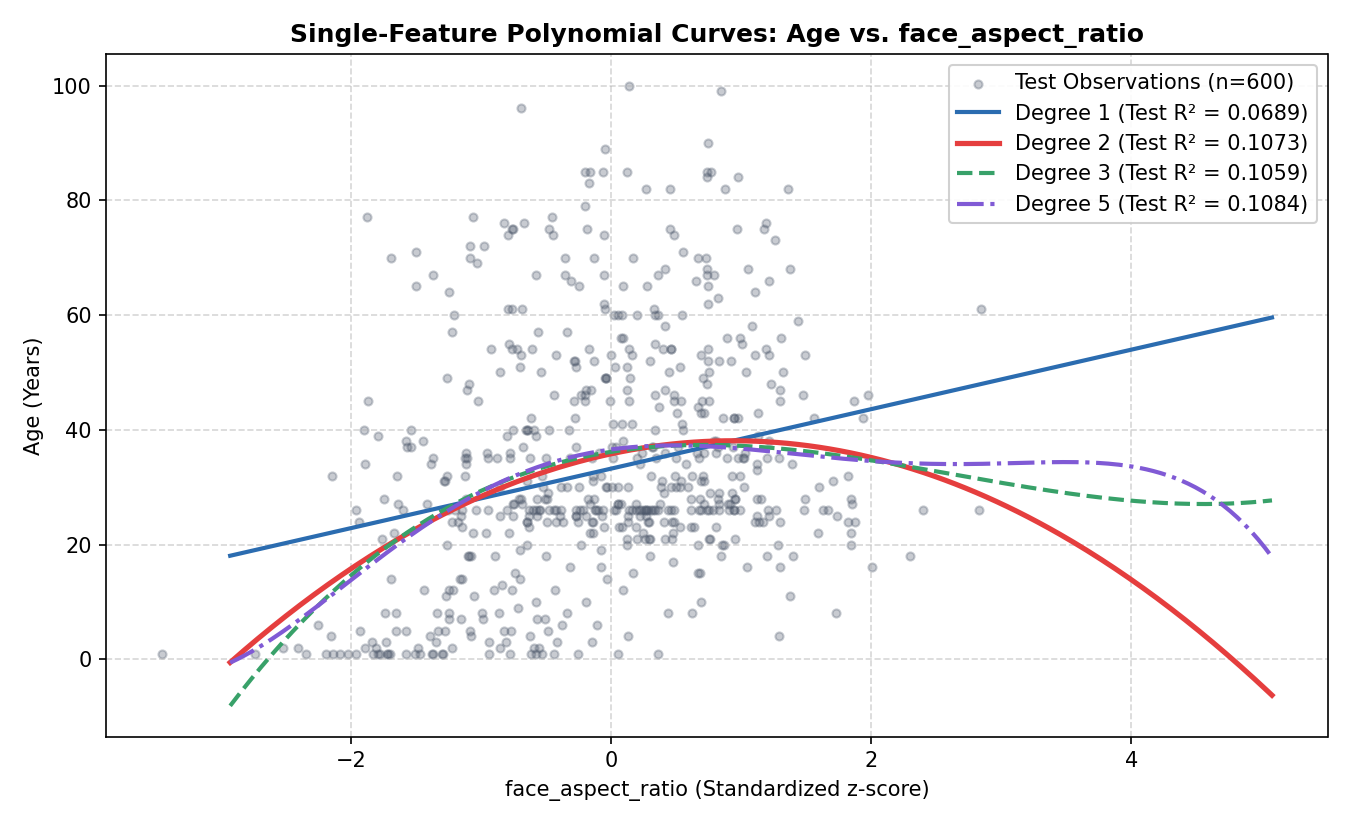

In [2]:
# Compute Pearson correlation on TRAINING data only to select best predictor dynamically
train_corrs = X_train_scaled[continuous_cols].apply(lambda col: col.corr(y_train))
best_feature = train_corrs.abs().idxmax()

print(f"Selected Best Continuous Feature for Single Polynomial: '{best_feature}' (r = {train_corrs[best_feature]:+.4f})")

# Fit single-feature polynomial models for degrees 1 through 5
single_poly_records = []
fitted_single_models = {}

for deg in range(1, 6):
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=deg, include_bias=False)),
        ('reg', LinearRegression())
    ])
    pipe.fit(X_train_scaled[[best_feature]], y_train)
    fitted_single_models[deg] = pipe
    
    y_tr_pred = pipe.predict(X_train_scaled[[best_feature]])
    y_te_pred = pipe.predict(X_test_scaled[[best_feature]])
    
    single_poly_records.append({
        "Degree": deg,
        "Train_R2": r2_score(y_train, y_tr_pred),
        "Test_R2": r2_score(y_test, y_te_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_te_pred))
    })

df_single_poly = pd.DataFrame(single_poly_records)
print("\n=== SINGLE-FEATURE POLYNOMIAL PERFORMANCE (Degrees 1 to 5) ===")
print(df_single_poly.round(4).to_string(index=False))

# Plot fitted polynomial curves over test observations
os.makedirs("visualizations", exist_ok=True)

# Generate smooth sorted grid spanning training range of best_feature
x_grid = np.linspace(
    X_train_scaled[best_feature].min(),
    X_train_scaled[best_feature].max(),
    300
).reshape(-1, 1)

plt.figure(figsize=(9, 5.5))
plt.scatter(
    X_test_scaled[best_feature],
    y_test,
    color="#4a5568",
    alpha=0.3,
    s=15,
    label="Test Observations (n=600)"
)

# Plot curves for degrees 1, 2, 3, and 5
curve_styles = {
    1: ("#2b6cb0", "-", 2.0),
    2: ("#e53e3e", "-", 2.5),
    3: ("#38a169", "--", 2.0),
    5: ("#805ad5", "-.", 2.0)
}

for deg, (col, lstyle, lwidth) in curve_styles.items():
    y_curve = fitted_single_models[deg].predict(x_grid)
    test_r2_val = df_single_poly.loc[df_single_poly['Degree'] == deg, 'Test_R2'].values[0]
    plt.plot(
        x_grid,
        y_curve,
        color=col,
        linestyle=lstyle,
        linewidth=lwidth,
        label=f"Degree {deg} (Test R² = {test_r2_val:.4f})"
    )

plt.title(f"Single-Feature Polynomial Curves: Age vs. {best_feature}", fontsize=12, fontweight="bold")
plt.xlabel(f"{best_feature} (Standardized z-score)", fontsize=10)
plt.ylabel("Age (Years)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()

# Save plot to file and show
plt.savefig("visualizations/08_polynomial_single_feature_curves.png", dpi=150)
plt.show()


In [3]:
# Factory function creating pipeline with selective continuous polynomial expansion
def make_poly_model(degree):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("poly", PolynomialFeatures(degree=degree, include_bias=False), continuous_cols),
            ("dummies", "passthrough", dummy_cols)
        ])),
        ("reg", LinearRegression())
    ])

# 5-Fold Cross-Validation on TRAINING data only
kf = KFold(n_splits=5, shuffle=True, random_state=42)

multi_poly_records = []

for deg in range(1, 5):
    # Fit full training pipeline
    model = make_poly_model(deg)
    model.fit(X_train_mlr, y_train)
    
    # Extract total number of expanded features
    n_expanded_features = model.named_steps["prep"].transform(X_train_mlr).shape[1]
    
    # Compute train and test metrics
    y_tr_pred = model.predict(X_train_mlr)
    y_te_pred = model.predict(X_test_mlr)
    
    # 5-Fold Cross-Validation on TRAINING data only
    cv_scores = cross_val_score(make_poly_model(deg), X_train_mlr, y_train, cv=kf, scoring="r2")
    
    multi_poly_records.append({
        "Degree": deg,
        "n_features": n_expanded_features,
        "Train_R2": r2_score(y_train, y_tr_pred),
        "CV_Mean_R2": cv_scores.mean(),
        "CV_Std_R2": cv_scores.std(),
        "Test_R2": r2_score(y_test, y_te_pred),
        "Test_MAE": mean_absolute_error(y_test, y_te_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_te_pred))
    })

df_multi_poly = pd.DataFrame(multi_poly_records)
print("=== MULTIVARIATE POLYNOMIAL REGRESSION SWEEP (Degrees 1 to 4) ===")
print(df_multi_poly.round(4).to_string(index=False))

# Verify that Degree 1 matches Multiple Linear Regression benchmark from Notebook 13
d1_train_r2 = df_multi_poly.loc[df_multi_poly['Degree'] == 1, 'Train_R2'].values[0]
d1_test_r2 = df_multi_poly.loc[df_multi_poly['Degree'] == 1, 'Test_R2'].values[0]
print(f"\nVerification check: Degree 1 Train R² = {d1_train_r2:.4f}, Test R² = {d1_test_r2:.4f} (Matches MLR: 0.1768, 0.1719).")


=== MULTIVARIATE POLYNOMIAL REGRESSION SWEEP (Degrees 1 to 4) ===
 Degree  n_features  Train_R2  CV_Mean_R2  CV_Std_R2  Test_R2  Test_MAE  Test_RMSE
      1          12    0.1768      0.1637     0.0139   0.1719   14.7200    19.1813
      2          40    0.1955      0.1427     0.0365   0.1785   14.6535    19.1044
      3         124    0.2254     -0.1060     0.3828   0.1366   14.7944    19.5859
      4         334    0.2613    -28.2882    34.0699  -0.3390   15.8008    24.3899

Verification check: Degree 1 Train R² = 0.1768, Test R² = 0.1719 (Matches MLR: 0.1768, 0.1719).


In [4]:
# Select best degree among genuine polynomial models (degrees 2, 3, 4) using CV Mean R2 only
poly_candidates = df_multi_poly[df_multi_poly['Degree'] >= 2]
best_degree_idx = poly_candidates['CV_Mean_R2'].idxmax()
best_degree = int(df_multi_poly.loc[best_degree_idx, 'Degree'])
best_cv_mean = df_multi_poly.loc[best_degree_idx, 'CV_Mean_R2']
best_cv_std = df_multi_poly.loc[best_degree_idx, 'CV_Std_R2']

print("=== POLYNOMIAL DEGREE SELECTION DECISION ===")
print(f"Selected Optimal Degree: {best_degree}")
print(f"Selection Criterion   : Highest 5-Fold Cross-Validation R² on TRAINING data ({best_cv_mean:.4f} ± {best_cv_std:.4f})")
print("Overfitting Diagnosis : Degrees 3 and 4 exhibit catastrophic negative CV scores and test R², demonstrating extreme variance.")

# Display markdown note emphasizing data leakage prevention
display(Markdown(
    f"> **Methodological Note:** The degree was selected **strictly using 5-Fold Cross-Validation on the training data** "
    f"(`CV_Mean_R2 = {best_cv_mean:.4f}` for Degree {best_degree}). The test set was **never used** to choose the degree. "
    f"Degree 1 is included in the sweep table solely as the linear reference baseline."
))


=== POLYNOMIAL DEGREE SELECTION DECISION ===
Selected Optimal Degree: 2
Selection Criterion   : Highest 5-Fold Cross-Validation R² on TRAINING data (0.1427 ± 0.0365)
Overfitting Diagnosis : Degrees 3 and 4 exhibit catastrophic negative CV scores and test R², demonstrating extreme variance.
<IPython.core.display.Markdown object>


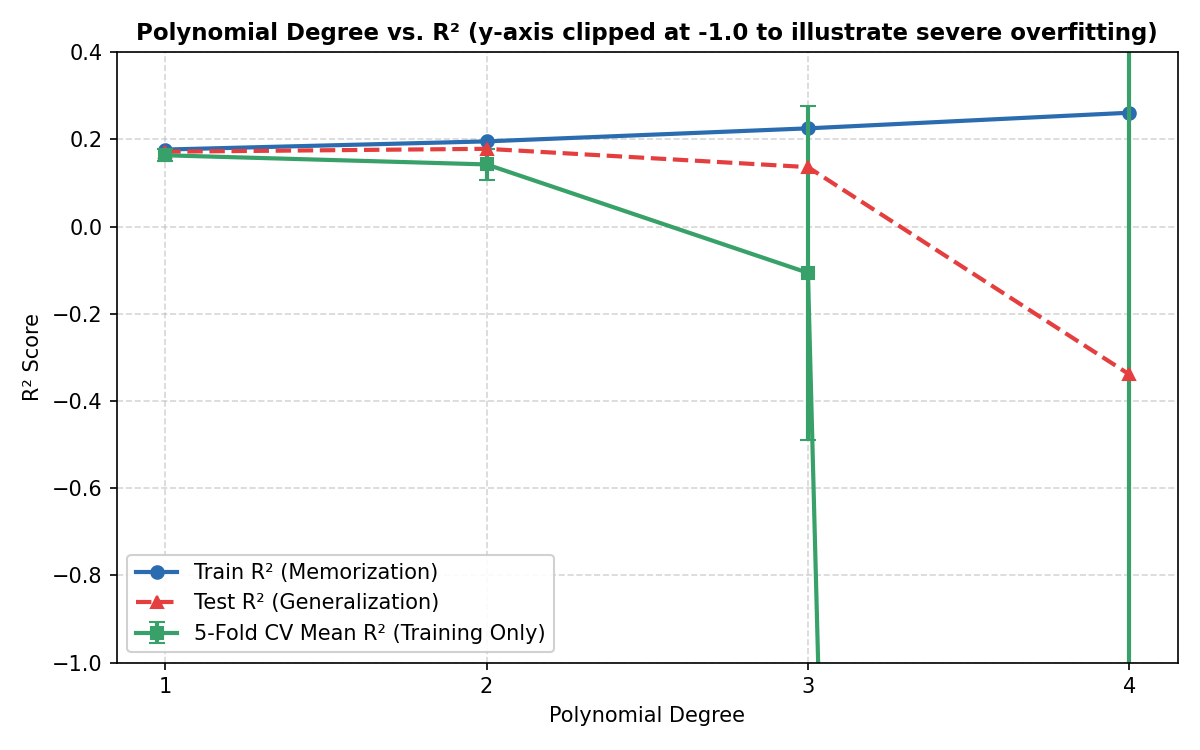

In [5]:
# Plot Degree vs Train R2, CV Mean R2, and Test R2
degrees = df_multi_poly['Degree']
train_r2s = df_multi_poly['Train_R2']
cv_means = df_multi_poly['CV_Mean_R2']
cv_stds = df_multi_poly['CV_Std_R2']
test_r2s = df_multi_poly['Test_R2']

plt.figure(figsize=(8, 5))

# Plot lines
plt.plot(degrees, train_r2s, marker='o', color='#2b6cb0', linewidth=2, label='Train R² (Memorization)')
plt.errorbar(degrees, cv_means, yerr=cv_stds, marker='s', color='#38a169', linewidth=2, capsize=4, label='5-Fold CV Mean R² (Training Only)')
plt.plot(degrees, test_r2s, marker='^', color='#e53e3e', linewidth=2, linestyle='--', label='Test R² (Generalization)')

# Check if any value is below -1 and clip y-axis
has_severe_negative = (cv_means.min() < -1.0) or (test_r2s.min() < -1.0)
if has_severe_negative:
    plt.ylim(-1.0, 0.4)
    plt.title("Polynomial Degree vs. R² (y-axis clipped at -1.0 to illustrate severe overfitting)", fontsize=11, fontweight="bold")
else:
    plt.title("Polynomial Degree vs. R²", fontsize=12, fontweight="bold")

plt.xlabel("Polynomial Degree", fontsize=10)
plt.ylabel("R² Score", fontsize=10)
plt.xticks(degrees)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()

# Save plot and show
plt.savefig("visualizations/09_polynomial_degree_sweep.png", dpi=150)
plt.show()


=== FINAL POLYNOMIAL REGRESSION MODEL (Degree 2) PERFORMANCE ===
  Model       : Polynomial Regression (degree 2)
  Train_MAE   : 13.6784
  Test_MAE    : 14.6535
  Train_MSE   : 323.6897
  Test_MSE    : 364.9775
  Train_RMSE  : 17.9914
  Test_RMSE   : 19.1044
  Train_R2    : 0.1955
  Test_R2     : 0.1785


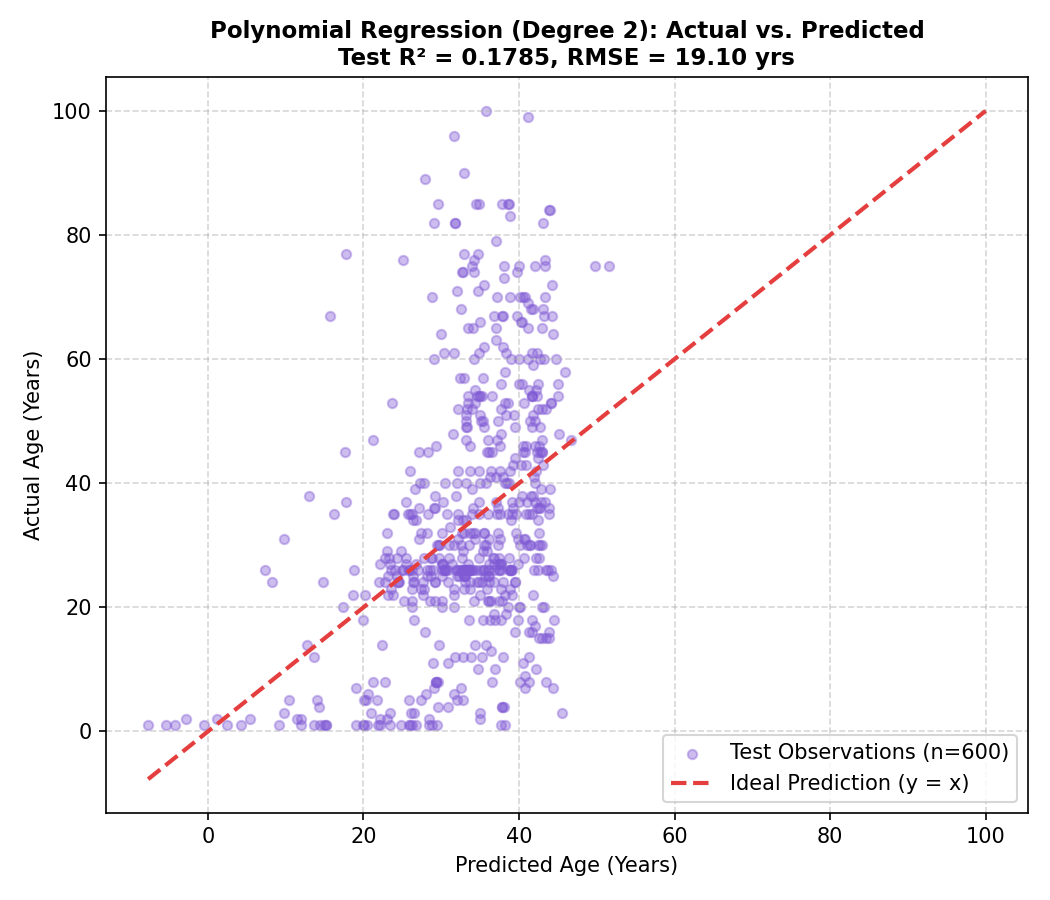

In [6]:
# Fit final polynomial model with chosen optimal degree
final_poly_model = make_poly_model(best_degree)
final_poly_model.fit(X_train_mlr, y_train)

# Evaluate final polynomial model
poly_results = evaluate(
    final_poly_model,
    X_train_mlr,
    y_train,
    X_test_mlr,
    y_test,
    f"Polynomial Regression (degree {best_degree})"
)

print(f"=== FINAL POLYNOMIAL REGRESSION MODEL (Degree {best_degree}) PERFORMANCE ===")
for metric, val in poly_results.items():
    if metric != "Model":
        print(f"  {metric:<12}: {val:.4f}")
    else:
        print(f"  {metric:<12}: {val}")

# Diagnostic Actual vs. Predicted plot on test set
y_test_pred_poly = final_poly_model.predict(X_test_mlr)

min_val = min(y_test.min(), y_test_pred_poly.min())
max_val = max(y_test.max(), y_test_pred_poly.max())

plt.figure(figsize=(7, 6))
plt.scatter(
    y_test_pred_poly,
    y_test,
    color="#805ad5",
    alpha=0.4,
    s=20,
    label="Test Observations (n=600)"
)
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="#e53e3e",
    linestyle="--",
    linewidth=2,
    label="Ideal Prediction (y = x)"
)

plt.title(
    f"Polynomial Regression (Degree {best_degree}): Actual vs. Predicted\n"
    f"Test R² = {poly_results['Test_R2']:.4f}, RMSE = {poly_results['Test_RMSE']:.2f} yrs",
    fontsize=11, fontweight="bold"
)
plt.xlabel("Predicted Age (Years)", fontsize=10)
plt.ylabel("Actual Age (Years)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white")
plt.tight_layout()

# Save diagnostic plot and show
plt.savefig("visualizations/10_actual_vs_predicted_polynomial.png", dpi=150)
plt.show()


In [7]:
# Load existing CE2 model results CSV
results_csv_path = "data/processed/ce2_model_results.csv"
results_df = pd.read_csv(results_csv_path)

# Drop any existing Polynomial Regression rows to prevent duplication on re-runs
results_df = results_df[~results_df['Model'].str.startswith("Polynomial")].copy()

# Append the new polynomial model results row
results_df = pd.concat([results_df, pd.DataFrame([poly_results])], ignore_index=True)

# Reorder columns consistently
columns_order = [
    "Model", "Train_MAE", "Test_MAE", "Train_RMSE", "Test_RMSE",
    "Train_R2", "Test_R2", "Train_MSE", "Test_MSE"
]
results_df = results_df[columns_order]

print("=== UPDATED CE2 REGRESSION MODELS PERFORMANCE SUMMARY ===")
print(results_df.round(4).to_string(index=False))

# Save updated DataFrame back to data/processed/ce2_model_results.csv
results_df.to_csv(results_csv_path, index=False)
print(f"\nUpdated results table saved successfully to '{results_csv_path}'.")


=== UPDATED CE2 REGRESSION MODELS PERFORMANCE SUMMARY ===
                           Model  Train_MAE  Test_MAE  Train_RMSE  Test_RMSE  Train_R2  Test_R2  Train_MSE  Test_MSE
                 Baseline (Mean)    15.5015   16.5798     20.0591    21.0996    0.0000  -0.0021   402.3679  445.1925
   Simple LR (face_aspect_ratio)    15.2493   16.1086     19.3774    20.3385    0.0668   0.0689   375.4821  413.6566
      Multiple Linear Regression    13.8583   14.7200     18.1997    19.1813    0.1768   0.1719   331.2289  367.9220
Polynomial Regression (degree 2)    13.6784   14.6535     17.9914    19.1044    0.1955   0.1785   323.6897  364.9775

Updated results table saved successfully to 'data/processed/ce2_model_results.csv'.


### Observation

*Placeholder for user observations on polynomial regression results, bias-variance tradeoff across degrees 1 to 4, cross-validation behavior, and final model comparison:*
- [Discuss the effect of increasing polynomial degree on single-feature curves and multivariate performance.]
- [Compare the 5-fold cross-validation scores across degrees 1, 2, 3, and 4 and identify the onset of severe overfitting.]
- [Analyze the marginal performance improvement (if any) gained by Degree 2 over the linear baseline.]
- [Examine the Actual vs. Predicted scatter plot for the final polynomial model and assess remaining residual patterns.]
